<a href="https://colab.research.google.com/github/SlukaLukas2/Neuronov-s-t-a-evolu-n-soustavy-NSES-AI---artifical-intelligence/blob/language/NSES_09_LLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch torchvision fasttext

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pybind11-3.1.0-py3-none-any.whl.metadata (10 kB)
Using cached pybind11-3.1.0-py3-none-any.whl (319 kB)
  Created wheel for fasttext: filename=fasttext-0.9.3-cp313-cp313-linux_x86_64.whl size=4711564 sha256=96c3a6844c64950b541ac2bbb182ac6a8b7f20192174e6921357b5323bb7a451
  Stored in directory: /root/.cache/pip/wheels/59/06/3f/c95dbba0df6e58ba6ed18220c1aea1e96042802139df3674ef
Successfully built fasttext
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [fasttext]


In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
with open('NSES_1_latex.txt', 'r', encoding='utf-8') as f:
    text_full = f.read()
print(text_full[:100])
text = text_full[:2000]

Budeš schopný si stáhnout.
To je peklo.
Já si to tedy ještě udělám možná trochu lépe, doufám.
Včera 


In [ ]:
# -----------------------------
# Byte-level tokenizer
# -----------------------------
class ByteTokenizer:
    def __init__(self):
        self.vocab_size = 256

    def encode(self, text: str) -> torch.Tensor:
        return torch.tensor(list(text.encode("utf-8")), dtype=torch.long)

    def decode(self, ids: torch.Tensor) -> str:
        # Clamp just in case and convert to bytes
        bytes_arr = bytes([int(x) % 256 for x in ids.cpu().tolist()])
        return bytes_arr.decode("utf-8", errors="replace")


In [ ]:
#-----------------------------
# Model components
# -----------------------------
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, block_size: int, dropout: float = 0.0):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

        # Causal mask (triangular)
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size))
                             .view(1, 1, block_size, block_size))

    def forward(self, x):
        B, T, C = x.size()
        qkv = self.qkv(x)  # (B, T, 3C)
        q, k, v = qkv.chunk(3, dim=-1)

        # Reshape to heads
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)  # (B, H, T, D)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        # Scaled dot-product attention
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)  # (B, H, T, T)
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        att = F.softmax(att, dim=-1)
        att = self.dropout(att)
        y = att @ v  # (B, H, T, D)

        # Merge heads
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.proj(y)
        return y


In [ ]:
class MLP(nn.Module):
    def __init__(self, d_model: int, expansion: int = 4, dropout: float = 0.0):
        super().__init__()
        self.fc1 = nn.Linear(d_model, expansion * d_model)
        self.fc2 = nn.Linear(expansion * d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.fc1(x)
        x = F.gelu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [ ]:
class DecoderBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, block_size: int, dropout: float = 0.0):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, block_size, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = MLP(d_model, expansion=4, dropout=dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

In [ ]:
class TinyDecoderOnlyLM(nn.Module):
    def __init__(self, vocab_size: int, d_model: int, n_layers: int, n_heads: int,
                 block_size: int, dropout: float = 0.0, weight_tie: bool = True):
        super().__init__()
        self.block_size = block_size
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            DecoderBlock(d_model, n_heads, block_size, dropout) for _ in range(n_layers)
        ])
        self.ln_f = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)

        if weight_tie:
            # Weight tying: lm_head.weight = token_emb.weight
            self.lm_head.weight = self.token_emb.weight

        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int):
        # idx: (B, T)
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits = self(idx_cond)
            logits = logits[:, -1, :]  # last time step
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.block_size, "Sequence length exceeds block_size"

        pos = torch.arange(0, T, device=idx.device).unsqueeze(0)
        x = self.token_emb(idx) + self.pos_emb(pos)
        x = self.drop(x)
        for blk in self.blocks:
            x = blk(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)

        if targets is None:
            return logits  # <-- return only logits during inference

        loss = F.cross_entropy(logits.view(B*T, -1), targets.view(B*T))
        return logits, loss



In [ ]:
# -----------------------------
# Data prep & training
# -----------------------------

device = "cuda" if torch.cuda.is_available() else "cpu"
losses: list[float] = []

def make_batches(data_ids: torch.Tensor, block_size: int, batch_size: int):
    # Random crop batches for language modeling
    ix = torch.randint(0, len(data_ids) - block_size - 1, (batch_size,))
    x = torch.stack([data_ids[i:i+block_size] for i in ix])
    y = torch.stack([data_ids[i+1:i+1+block_size] for i in ix])
    return x, y

def train_and_generate(
    text: str,
    n_layers: int,
    n_heads: int,
    d_model: int = 256,
    block_size: int = 128,
    steps: int = 1000,
    batch_size: int = 32,
    lr: float = 3e-4,
    dropout: float = 0.0,
    seed: int = 1337,
    gen_prompt: str = "Ahoj",
    max_new_tokens: int = 200,
):
    torch.manual_seed(seed)


    tokenizer = ByteTokenizer()
    data_ids = tokenizer.encode(text)

    if len(data_ids) < block_size + 2:
        raise ValueError("Text too short for the chosen block_size.")

    model = TinyDecoderOnlyLM(
        vocab_size=tokenizer.vocab_size,
        d_model=d_model,
        n_layers=n_layers,
        n_heads=n_heads,
        block_size=block_size,
        dropout=dropout,
        weight_tie=True,
    ).to(device)

    print(model)
    print(f"Model parameters: {sum(p.numel() for p in model.parameters())}")

    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)

    data_ids = data_ids.to(device)
    model.train()
    for step in range(steps):
        x, y = make_batches(data_ids, block_size, batch_size)
        x, y = x.to(device), y.to(device)

        logits, loss = model(x, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()

        L = float(loss.item())
        losses.append(L)

        if (step + 1) % max(1, steps // 10) == 0:
            print(f"step {step+1}/{steps} - loss {loss.item():.4f}")

    # Generate
    model.eval()
    with torch.no_grad():
        prompt_ids = tokenizer.encode(gen_prompt).unsqueeze(0).to(device)  # (1, T)
        out_ids = model.generate(prompt_ids, max_new_tokens=max_new_tokens)[0]
        generated = tokenizer.decode(out_ids)

    print("\n=== SAMPLE ===")
    print(generated)
    return model, tokenizer


In [ ]:
sample_text = ("Ahoj světe! č, š, ř — funguje to?\n" * 500) + \
                  "Toto je malý příklad tréninku autoregresivního dekodéru.\n"

# Quick demo run:
model, tokenizer = train_and_generate(sample_text, n_layers=4, n_heads=4, d_model=256,
                       steps=500, block_size=128, gen_prompt="Ahoj", max_new_tokens=200)

TinyDecoderOnlyLM(
  (token_emb): Embedding(256, 256)
  (pos_emb): Embedding(128, 256)
  (drop): Dropout(p=0.0, inplace=False)
  (blocks): ModuleList(
    (0-3): 4 x DecoderBlock(
      (ln1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): CausalSelfAttention(
        (qkv): Linear(in_features=256, out_features=768, bias=False)
        (proj): Linear(in_features=256, out_features=256, bias=False)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ln2): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): MLP(
        (fc1): Linear(in_features=256, out_features=1024, bias=True)
        (fc2): Linear(in_features=1024, out_features=256, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (ln_f): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
  (lm_head): Linear(in_features=256, out_features=256, bias=False)
)
Model parameters: 3253760
step 50/500 - loss 0.2954
step 100/500 -

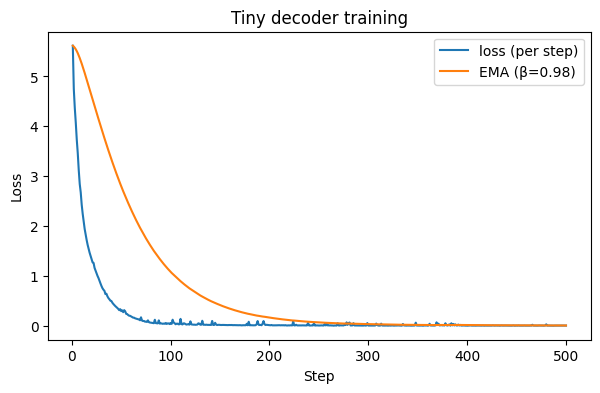

In [ ]:
# --- additions / changes ---

import matplotlib.pyplot as plt
import math

def plot_loss(losses, ema_beta: float | None = 0.98, figsize=(7, 4), title="Training loss"):
    """
    Plot raw step-wise loss and (optionally) an EMA-smoothed curve.
    - losses: list[float] collected during training (one per step)
    - ema_beta: if None, no EMA; else use beta in [0,1) for smoothing (default 0.98)
    """
    if not losses:
        raise ValueError("No losses to plot.")
    steps = list(range(1, len(losses) + 1))

    plt.figure(figsize=figsize)
    plt.plot(steps, losses, label="loss (per step)")

    if ema_beta is not None:
        ema = []
        m = None
        for L in losses:
            m = L if m is None else (ema_beta * m + (1 - ema_beta) * L)
            ema.append(m)
        plt.plot(steps, ema, label=f"EMA (β={ema_beta})")

    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.show()

plot_loss(losses, ema_beta=0.98, title="Tiny decoder training")

In [ ]:
print(text_full[:100])

# Quick demo run:
model, tokenizer = train_and_generate(text_full, n_layers=8, n_heads=4, d_model=256,
                       steps=10000, block_size=128, gen_prompt="gradienty", max_new_tokens=200)

Budeš schopný si stáhnout.
To je peklo.
Já si to tedy ještě udělám možná trochu lépe, doufám.
Včera 
TinyDecoderOnlyLM(
  (token_emb): Embedding(256, 256)
  (pos_emb): Embedding(128, 256)
  (drop): Dropout(p=0.0, inplace=False)
  (blocks): ModuleList(
    (0-7): 8 x DecoderBlock(
      (ln1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): CausalSelfAttention(
        (qkv): Linear(in_features=256, out_features=768, bias=False)
        (proj): Linear(in_features=256, out_features=256, bias=False)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ln2): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): MLP(
        (fc1): Linear(in_features=256, out_features=1024, bias=True)
        (fc2): Linear(in_features=1024, out_features=256, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (ln_f): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
  (lm_head): Linear(in_features=25

In [ ]:
# Generate
model.eval()
with torch.no_grad():
    prompt_ids = tokenizer.encode("Studenti na zkoušce").unsqueeze(0).to(device)  # (1, T)
    out_ids = model.generate(prompt_ids, max_new_tokens=200)[0]
    generated = tokenizer.decode(out_ids)
print(generated)

Studenti na zkoušce. Přečtěte to? Cosne similarity. Cosne similarity je už takovej trošku odhodenej z toho. A jako political correctness filter. Ano, ještě, ještě, ještě. Protože to nemůžeme dohlně si do 
